#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester, backtester_v2
from src.strategies import run_momentum_strategy
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

returns_array = np.array(returns)
prices_array = np.array(prices)

valid_days = len(prices) - lookback - 1
possible_trade_days = np.arange(lookback + 1, len(prices_array) - 1)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
time_invested = momentum_results["time_invested"]

#### Exposure & Trade-Count Matched Strategy

In [4]:
def generate_random_signal_v4(prices, lookback):

    valid_days = len(prices) - lookback - 1

    time_invested = momentum_results["time_invested"]

    invested_days = round(valid_days * time_invested)
    cash_days = valid_days - invested_days

    invested_trade_days = np.random.choice(np.arange(1, invested_days), size = 44, replace = False)
    invested_trade_days = np.sort(invested_trade_days)
    
    invested_runs = [invested_trade_days[0]]
    
    for i in range(1,len(invested_trade_days)):
    
        run_length = invested_trade_days[i] - invested_trade_days[i - 1]
        invested_runs.append(run_length)
    
    invested_runs.append(invested_days - invested_trade_days[-1])
    
    
    cash_trade_days = np.random.choice(np.arange(1, cash_days), size = 44, replace = False)
    cash_trade_days = np.sort(cash_trade_days)
    
    cash_runs = [cash_trade_days[0]]
    
    for i in range(1,len(cash_trade_days)):
    
        run_length = cash_trade_days[i] - cash_trade_days[i - 1]
        cash_runs.append(run_length)
    
    cash_runs.append(cash_days - cash_trade_days[-1])
    
    sequence = []
    
    for i in range(len(cash_runs)):
    
        sequence.extend([0] * cash_runs[i])
        sequence.extend([1] * invested_runs[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal
    
    

In [5]:
def generate_random_signal_v4_optimised(prices_array, lookback):   

    valid_days = len(prices_array) - lookback - 1

    invested_days = round(time_invested * valid_days)

    invested_internal_boundaries = np.random.choice(np.arange(1, invested_days), size = 44, replace = False)

    invested_boundaries = np.concatenate(([0], invested_internal_boundaries, [invested_days]))
    invested_boundaries = np.sort(invested_boundaries)

    invested_runs = np.diff(invested_boundaries)

    cash_days = valid_days - invested_days

    cash_internal_boundaries = np.random.choice(np.arange(1, cash_days), size = 44, replace = False)

    cash_boundaries = np.concatenate(([0], cash_internal_boundaries, [cash_days]))
    cash_boundaries = np.sort(cash_boundaries)

    cash_runs = np.diff(cash_boundaries)

    run_lengths = np.empty(90, dtype=int)

    run_lengths[::2] = cash_runs
    run_lengths[1::2] = invested_runs

    states = np.tile([0, 1], 45)

    sequence = np.repeat(states, run_lengths)

    random_signal = np.concatenate(([np.nan] * lookback, sequence, [np.nan]))

    return random_signal

In [6]:
def run_simulation_v4(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v4(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [7]:
def run_simulation_v4_optimised(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v4_optimised(prices_array, lookback)
        random_result = backtester_v2(returns_array, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [8]:
np.random.seed(44)

simulation_output = run_simulation_v4_optimised(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,4.169497,0.066181,0.162721,0.475374,-0.428958,0.154284,0.775232,89
1,5.254369,0.074134,0.162634,0.521222,-0.422528,0.175454,0.775232,89
2,7.556949,0.087349,0.160339,0.602569,-0.378351,0.230869,0.775232,89
3,4.900737,0.071698,0.174828,0.483541,-0.541605,0.132381,0.775232,89
4,2.851770,0.054014,0.170531,0.393835,-0.564419,0.095698,0.775232,89
...,...,...,...,...,...,...,...,...
99995,2.593666,0.051166,0.165354,0.384549,-0.452960,0.112958,0.775232,89
99996,3.248160,0.058049,0.168575,0.419006,-0.469368,0.123674,0.775232,89
99997,4.036137,0.065095,0.169003,0.457534,-0.448795,0.145044,0.775232,89
99998,4.252070,0.066841,0.166265,0.472276,-0.603296,0.110793,0.775232,89


Mean Sharpe: 0.46942
Median Sharpe: 0.46408
Max Sharpe: 0.94609
P Value: 0.04709
Avg Trades: 89
Avg Time Invested: 0.77523
Number Of Simulations: 100000


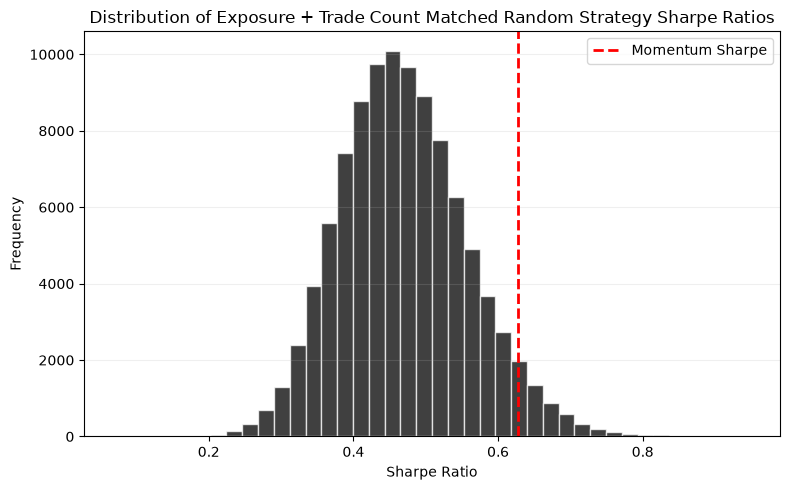

In [9]:
exposure_trade_count_summary = summary(simulation_df, momentum_results, "exposure_+_trade_count_matched_random_strategy")